# Airline Passenger Satisfaction — Data Cleaning and Exploratory Analysis

## Objective
This notebook cleans the airline passenger dataset and explores passenger satisfaction, waiting times, airline and destination patterns, and service ratings.

**Workflow**
1. Load and inspect the dataset.
2. Standardize text and categories.
3. Check missing values, duplicates, data types, and possible invalid values.
4. Explore the main variables.
5. Compare satisfaction and waiting times across groups.


## 1. Import libraries and load the data

In [256]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)

df = pd.read_csv("airlines_final.csv", index_col=0)

# Preview the records and check the shape of the dataset.
display(df.head())
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print("Column names:", df.columns.tolist())

,id,day,airline,destination,dest_region,dest_size,boarding_area,dept_time,wait_min,cleanliness,safety,satisfaction
0,1351,Tuesday,UNITED INTL,KANSAI,Asia,Hub,Gates 91-102,2018-12-31,115.0,Clean,Neutral,Very satisfied
1,373,Friday,ALASKA,SAN JOSE DEL CABO,Canada/Mexico,Small,Gates 50-59,2018-12-31,135.0,Clean,Very safe,Very satisfied
2,2820,Thursday,DELTA,LOS ANGELES,West US,Hub,Gates 40-48,2018-12-31,70.0,Average,Somewhat safe,Neutral
3,1157,Tuesday,SOUTHWEST,LOS ANGELES,West US,Hub,Gates 20-39,2018-12-31,190.0,Clean,Very safe,Somewhat satsified
4,2992,Wednesday,AMERICAN,MIAMI,East US,Hub,Gates 50-59,2018-12-31,559.0,Somewhat clean,Very safe,Somewhat satsified


Rows: 2,477
Columns: 12
Column names: ['id', 'day', 'airline', 'destination', 'dest_region', 'dest_size', 'boarding_area', 'dept_time', 'wait_min', 'cleanliness', 'safety', 'satisfaction']


## 2. Inspect the schema
Review the data types and a sample of values before changing columns. The listed fields include passenger/day/airline/destination categories, waiting time, and service/satisfaction ratings.

In [257]:
# Check column data types, non-null counts, and memory usage.
df.info()

# Summary statistics for all columns, including categorical columns.
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
Index: 2477 entries, 0 to 2808
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2477 non-null   int64  
 1   day            2477 non-null   str    
 2   airline        2477 non-null   str    
 3   destination    2477 non-null   str    
 4   dest_region    2477 non-null   str    
 5   dest_size      2477 non-null   str    
 6   boarding_area  2477 non-null   str    
 7   dept_time      2477 non-null   str    
 8   wait_min       2477 non-null   float64
 9   cleanliness    2477 non-null   str    
 10  safety         2477 non-null   str    
 11  satisfaction   2477 non-null   str    
dtypes: float64(1), int64(1), str(10)
memory usage: 479.1 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2477.0,NaN,NaN,NaN,1813.363746,945.226305,1.0,1038.0,1859.0,2581.0,9004.0
day,2477,7,Tuesday,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airline,2477,33,UNITED,526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,2477,72,LOS ANGELES,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dest_region,2477,12,West US,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dest_size,2477,12,Hub,1202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boarding_area,2477,7,Gates 1-12,609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dept_time,2477,2,2018-12-31,2440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wait_min,2477.0,NaN,NaN,NaN,166.084376,107.643625,15.0,105.0,145.0,185.0,1365.0
cleanliness,2477,5,Somewhat clean,1175,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Standardize text and fix known spelling inconsistencies
Trim extra spaces and standardize capitalization in text fields. Correct only spelling variants that are known to refer to the same category. Keep distinct destination regions distinct.

In [258]:
# Standardize whitespace and capitalization for selected text columns.
text_columns = [
    "day", "airline", "destination", "dest_region",
    "dest_size", "boarding_area", "cleanliness",
    "safety", "satisfaction"
]

for column in text_columns:
    if column in df.columns:
        df[column] = (
            df[column]
            .astype("string")
            .str.strip()
            .str.replace(r"\\s+", " ", regex=True)
        )

# Consistent title case for commonly displayed category fields.
for column in ["day", "airline", "destination", "dest_region",
               "dest_size", "boarding_area"]:
    if column in df.columns:
        df[column] = df[column].str.title()

# Correct the known satisfaction spelling variant.
if "satisfaction" in df.columns:
    df["satisfaction"] = df["satisfaction"].replace({
        "Somewhat Satsified": "Somewhat Satisfied"
    })

# Correct a known abbreviated region label without combining distinct regions.
if "dest_region" in df.columns:
    df["dest_region"] = df["dest_region"].replace({
        "Eur": "Europe",
        "Middle east": "Middle East"
    })

# Show the category values after standardization.
for column in text_columns:
    if column in df.columns:
        print(f"\\n{column}:")
        print(sorted(df[column].dropna().unique().tolist()))

\nday:
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
\nairline:
['Aer Lingus', 'Aeromexico', 'Air Canada', 'Air China', 'Air France/Klm', 'Air New Zealand', 'Alaska', 'American', 'Ana All Nippon', 'Avianca', 'British Airways', 'Cathay Pacific', 'China Eastern', 'China Southern', 'Copa', 'Delta', 'Emirates', 'Eva Air', 'Frontier', 'Hawaiian Air', 'Interjet', 'Jetblue', 'Korean Air', 'Lufthansa', 'Philippine Airlines', 'Qantas', 'Singapore Airlines', 'Southwest', 'Turkish Airlines', 'United', 'United Intl', 'Virgin Atlantic', 'Wow']
\ndestination:
['Amsterdam', 'Atlanta', 'Auckland', 'Austin', 'Bakersfield', 'Baltimore', 'Beijing', 'Boston', 'Burbank', 'Calgary', 'Charlotte', "Chicago-O'Hare", 'Dallas-Ft. Worth', 'Denver', 'Detroit', 'Dubai', 'Dublin', 'Eugene', 'Frankfurt', 'Ft. Lauderdale', 'Guadalajara', 'Hong Kong', 'Honolulu', 'Houston-Bush', 'Indianapolis', 'Istanbul', 'Kahului', 'Kansai', 'Kansas City', 'Las Vegas', 'London Heathrow', 'Long Beach',

## 4. Convert numeric columns and validate values
Waiting time should be numeric for summaries and comparisons. Conversion errors become missing values so they can be inspected rather than silently treated as valid numbers.

In [259]:
# Convert wait_min to numeric. Invalid strings become NaN.
if "wait_min" in df.columns:
    df["wait_min"] = pd.to_numeric(df["wait_min"], errors="coerce")

# Check for negative waiting times, which are usually invalid.
if "wait_min" in df.columns:
    invalid_wait = df["wait_min"] < 0
    print("Negative waiting-time records:", int(invalid_wait.sum()))
    # Do not automatically delete these rows; inspect them first if any exist.
    display(df.loc[invalid_wait].head())

Negative waiting-time records: 0


,id,day,airline,destination,dest_region,dest_size,boarding_area,dept_time,wait_min,cleanliness,safety,satisfaction


## 5. Check missing values and duplicates

In [260]:
# Number of missing values per column.
missing_counts = df.isnull().sum().sort_values(ascending=False)
display(missing_counts)

# Count exact duplicate rows.
print("Exact duplicate rows:", int(df.duplicated().sum()))

id               0
day              0
airline          0
destination      0
dest_region      0
dest_size        0
boarding_area    0
dept_time        0
wait_min         0
cleanliness      0
safety           0
satisfaction     0
dtype: int64

Exact duplicate rows: 0


## 6. Review category frequencies

In [261]:
categorical_columns = [
    "day", "airline", "destination", "dest_region",
    "dest_size", "boarding_area", "cleanliness",
    "safety", "satisfaction"
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\\nTop categories for {column}:")
        display(df[column].value_counts(dropna=False).head(10))

\nTop categories for day:


day
Tuesday      535
Wednesday    518
Thursday     488
Friday       368
Sunday       267
Saturday     210
Monday        91
Name: count, dtype: int64[pyarrow]

\nTop categories for airline:


airline
United            526
Alaska            315
Southwest         184
American          175
Delta             170
United Intl       155
Jetblue           144
Air Canada        133
Air France/Klm    120
Cathay Pacific     81
Name: count, dtype: int64[pyarrow]

\nTop categories for destination:


...

cleanliness
Somewhat clean    1175
Clean              885
Average            389
Somewhat dirty      26
Dirty                2
Name: count, dtype: int64[pyarrow]

\nTop categories for safety:


safety
Very safe          1296
Somewhat safe       864
Neutral             303
Very unsafe           8
Somewhat unsafe       6
Name: count, dtype: int64[pyarrow]

\nTop categories for satisfaction:


satisfaction
Somewhat satsified      1349
Very satisfied           596
Neutral                  486
Somewhat unsatisfied      42
Very unsatisfied           4
Name: count, dtype: int64[pyarrow]

## 7. Visualize the main distributions

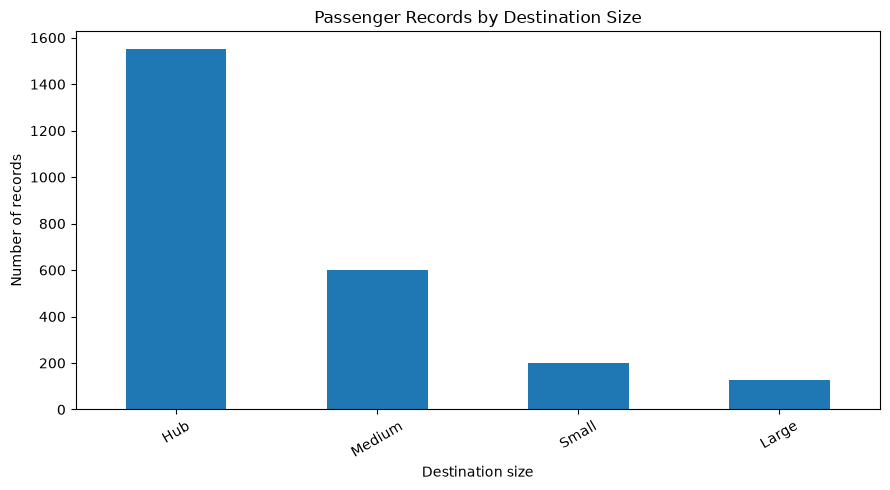

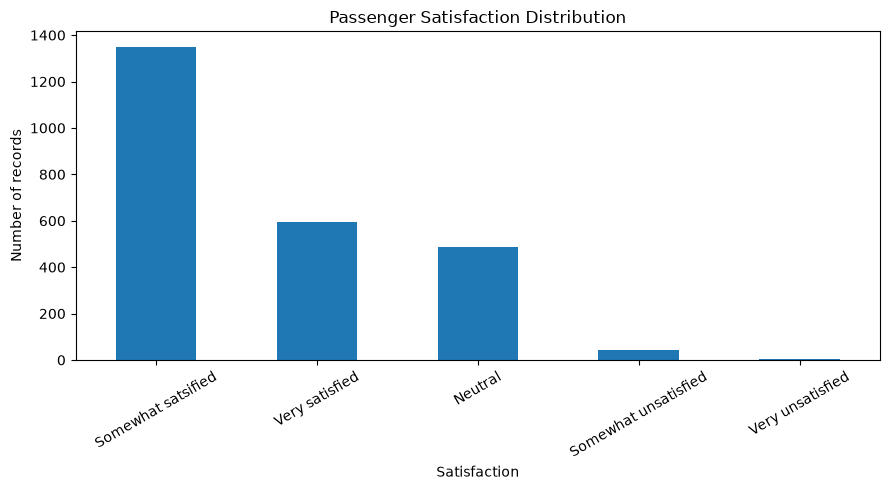

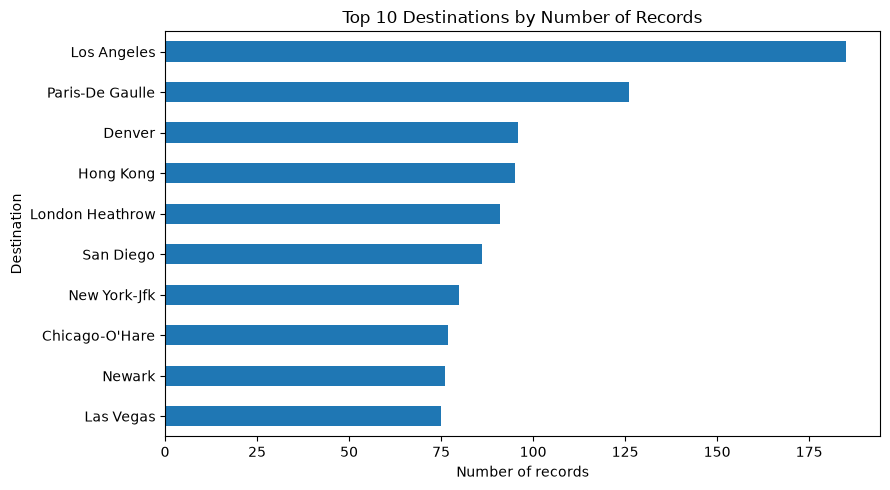

In [262]:
# Destination size distribution.
if "dest_size" in df.columns:
    ax = df["dest_size"].value_counts().plot(kind="bar", rot=30)
    ax.set_title("Passenger Records by Destination Size")
    ax.set_xlabel("Destination size")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()

# Full satisfaction distribution.
if "satisfaction" in df.columns:
    ax = df["satisfaction"].value_counts().plot(kind="bar", rot=30)
    ax.set_title("Passenger Satisfaction Distribution")
    ax.set_xlabel("Satisfaction")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()

# Most common destinations.
if "destination" in df.columns:
    ax = df["destination"].value_counts().head(10).sort_values().plot(kind="barh")
    ax.set_title("Top 10 Destinations by Number of Records")
    ax.set_xlabel("Number of records")
    ax.set_ylabel("Destination")
    plt.tight_layout()
    plt.show()

## 8. Waiting-time analysis

,wait_min
count,2477.000000
mean,166.084376
std,107.643625
min,15.000000
25%,105.000000
50%,145.000000
75%,185.000000
90%,263.000000
95%,336.000000
max,1365.000000


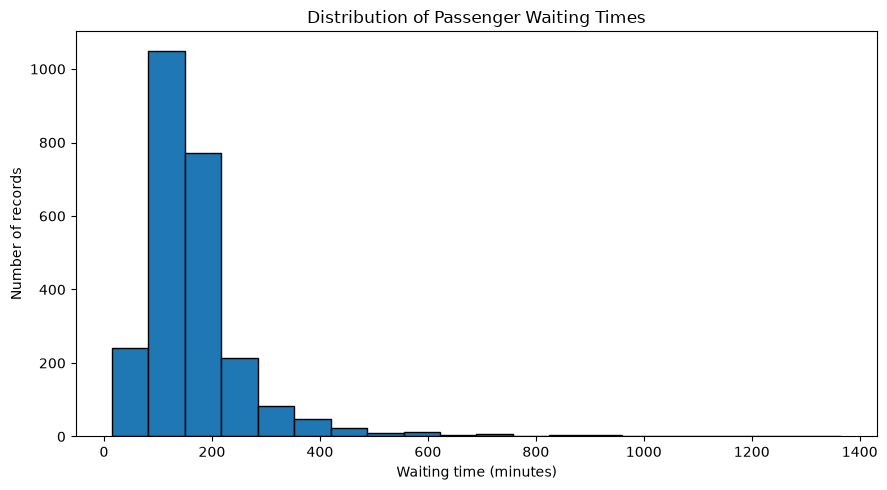

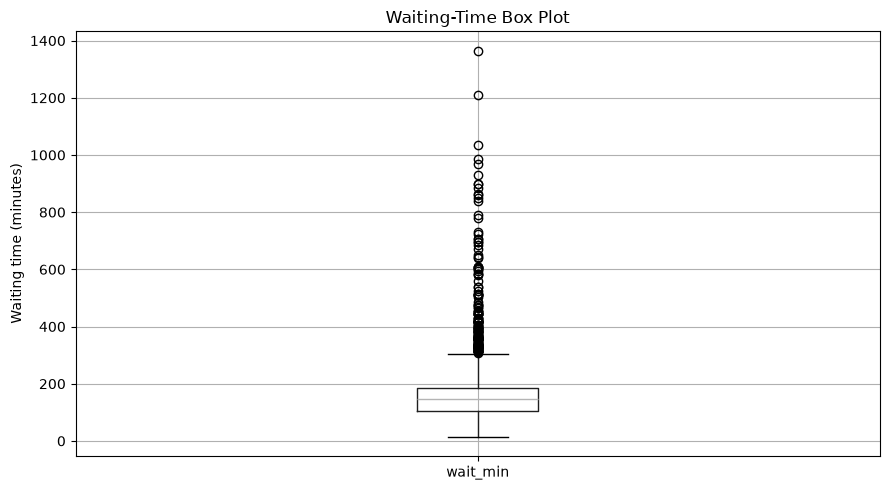

In [263]:
if "wait_min" in df.columns:
    wait_summary = df["wait_min"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    ).to_frame(name="wait_min")
    display(wait_summary)

    ax = df["wait_min"].dropna().plot(kind="hist", bins=20, edgecolor="black")
    ax.set_title("Distribution of Passenger Waiting Times")
    ax.set_xlabel("Waiting time (minutes)")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()

    ax = df.boxplot(column="wait_min")
    ax.set_title("Waiting-Time Box Plot")
    ax.set_ylabel("Waiting time (minutes)")
    plt.tight_layout()
    plt.show()

## 9. Waiting time by day

,records,mean_wait,median_wait
day,,,
Tuesday,535,147.29,120.0
Thursday,488,153.48,130.0
Saturday,210,163.73,155.0
Wednesday,518,174.63,153.0
Friday,368,178.18,155.0
Sunday,267,180.51,160.0
Monday,91,209.71,175.0


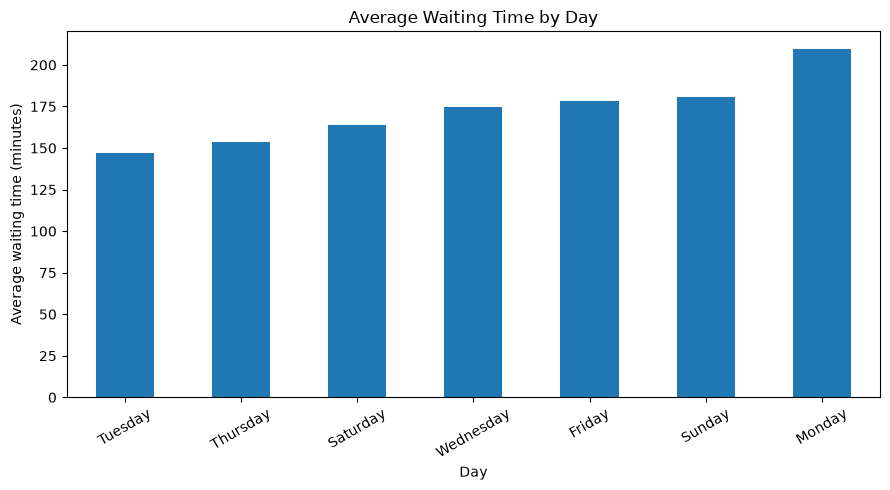

In [264]:
if {"day", "wait_min"}.issubset(df.columns):
    wait_by_day = (
        df.groupby("day", dropna=False)["wait_min"]
        .agg(records="count", mean_wait="mean", median_wait="median")
        .sort_values("mean_wait")
    )
    display(wait_by_day.round(2))

    ax = wait_by_day["mean_wait"].plot(kind="bar", rot=30)
    ax.set_title("Average Waiting Time by Day")
    ax.set_xlabel("Day")
    ax.set_ylabel("Average waiting time (minutes)")
    plt.tight_layout()
    plt.show()

## 10. Satisfaction by airline and boarding area

In [265]:
def satisfaction_percent_by(group_column):
    # Returns row percentages: each group's satisfaction categories add to 100%.
    table = pd.crosstab(
        df[group_column],
        df["satisfaction"],
        normalize="index"
    ).mul(100)
    return table.round(1)

if {"airline", "satisfaction"}.issubset(df.columns):
    print("Satisfaction percentage by airline:")
    display(satisfaction_percent_by("airline"))

if {"boarding_area", "satisfaction"}.issubset(df.columns):
    print("Satisfaction percentage by boarding area:")
    display(satisfaction_percent_by("boarding_area"))

Satisfaction percentage by airline:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
airline,,,,,
Aer Lingus,27.8,55.6,0.0,16.7,0.0
Aeromexico,45.5,45.5,0.0,9.1,0.0
Air Canada,26.3,51.9,2.3,19.5,0.0
Air China,37.5,37.5,0.0,25.0,0.0
Air France/Klm,29.2,51.7,0.8,17.5,0.8
Air New Zealand,14.3,52.4,0.0,33.3,0.0
Alaska,16.8,53.3,1.6,28.3,0.0
American,15.4,53.1,0.6,30.9,0.0
Ana All Nippon,50.0,50.0,0.0,0.0,0.0


Satisfaction percentage by boarding area:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
boarding_area,,,,,
Gates 1-12,24.1,54.2,3.0,18.4,0.3
Gates 20-39,21.3,52.4,1.8,24.4,0.0
Gates 40-48,25.0,54.0,2.8,17.6,0.6
Gates 50-59,16.3,53.1,1.1,29.6,0.0
Gates 60-69,13.3,53.1,1.4,32.2,0.0
Gates 70-90,15.4,57.2,0.8,26.4,0.3
Gates 91-102,19.6,55.5,1.1,23.8,0.0


## 11. Service ratings and satisfaction

In [266]:
for rating_column in ["cleanliness", "safety"]:
    if {rating_column, "satisfaction"}.issubset(df.columns):
        print(f"\\nSatisfaction by {rating_column}:")
        display(pd.crosstab(
            df[rating_column],
            df["satisfaction"],
            normalize="index"
        ).mul(100).round(1))

\nSatisfaction by cleanliness:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
cleanliness,,,,,
Average,48.8,40.9,6.4,3.3,0.5
Clean,6.2,41.6,0.2,51.9,0.1
Dirty,50.0,0.0,0.0,0.0,50.0
Somewhat clean,19.1,69.5,0.9,10.6,0.0
Somewhat dirty,61.5,19.2,19.2,0.0,0.0


\nSatisfaction by safety:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
safety,,,,,
Neutral,40.3,43.6,5.3,10.6,0.3
Somewhat safe,23.4,61.2,2.0,13.1,0.3
Somewhat unsafe,33.3,50.0,16.7,0.0,0.0
Very safe,12.3,52.6,0.6,34.5,0.0
Very unsafe,12.5,37.5,0.0,50.0,0.0


## 12. Explore destination characteristics

In [267]:
for group_column in ["dest_region", "dest_size"]:
    if {group_column, "satisfaction"}.issubset(df.columns):
        print(f"\\nSatisfaction by {group_column}:")
        display(pd.crosstab(
            df[group_column],
            df["satisfaction"],
            normalize="index"
        ).mul(100).round(1))

if {"dest_region", "wait_min"}.issubset(df.columns):
    display(
        df.groupby("dest_region", dropna=False)["wait_min"]
        .agg(records="count", mean_wait="mean", median_wait="median")
        .sort_values("mean_wait")
        .round(2)
    )

\nSatisfaction by dest_region:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
dest_region,,,,,
Asia,19.9,55.3,0.4,24.3,0.0
Australia/New Zealand,26.7,46.7,5.0,21.7,0.0
Canada/Mexico,21.2,55.6,2.0,21.2,0.0
Central/South America,18.2,45.5,4.5,31.8,0.0
East Us,18.1,55.3,0.7,25.7,0.2
Europe,23.6,57.3,2.8,16.0,0.3
Middle East,17.4,49.3,2.9,30.4,0.0
Midwest Us,14.7,56.6,0.8,27.9,0.0
West Us,19.4,53.0,1.9,25.5,0.2


\nSatisfaction by dest_size:


satisfaction,Neutral,Somewhat satsified,Somewhat unsatisfied,Very satisfied,Very unsatisfied
dest_size,,,,,
Hub,21.4,52.5,1.9,24.1,0.2
Large,19.7,61.4,0.8,18.1,0.0
Medium,17.5,55.7,1.5,25.3,0.0
Small,12.0,62.0,1.5,24.0,0.5


,records,mean_wait,median_wait
dest_region,,,
West Us,864,143.52,120.0
Midwest Us,251,146.04,120.0
East Us,436,146.61,125.0
Central/South America,22,187.64,159.0
Canada/Mexico,198,189.29,150.0
Asia,226,194.85,185.0
Europe,351,204.18,180.0
Middle East,69,204.55,195.0
Australia/New Zealand,60,256.42,212.5


## 13. Check possible relationships between numerical variables

,id,wait_min
id,1.00,-0.02
wait_min,-0.02,1.00


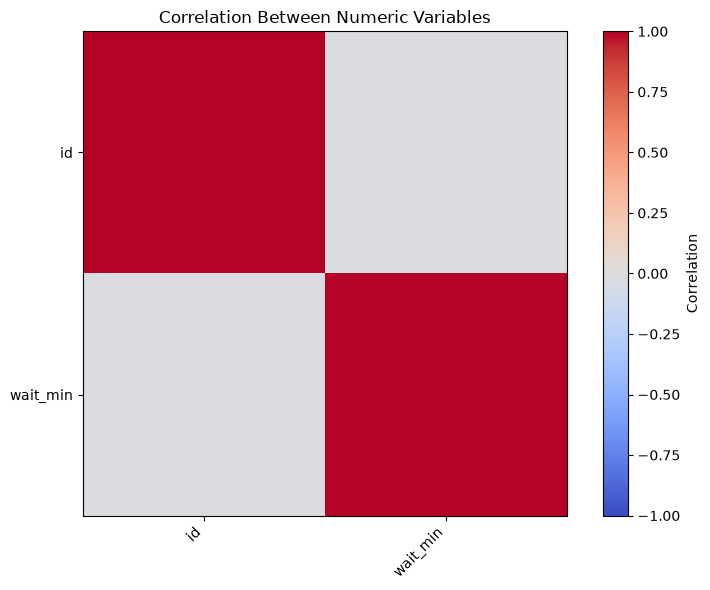

In [268]:
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr(numeric_only=True)
    display(corr.round(2))

    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)), corr.index)
    ax.set_title("Correlation Between Numeric Variables")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")